<a href="https://colab.research.google.com/github/JasmineNasywa/PCVK_Ganjil_2026/blob/main/Week10_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import Library
import cv2 as cv
import numpy as np
import os
import random
import pickle
from matplotlib import pyplot as plt
from tqdm import tqdm

In [2]:
# Akses Drive
from google.colab import drive
drive.mount('/content/drive')
PCVK = '/content/drive/MyDrive/PCVK'

Mounted at /content/drive


In [6]:
# Fungsi Bantu
indeks = {}
for akar, _, berkas in os.walk(PCVK):
    for b in berkas:
        indeks[b.lower()] = os.path.join(akar, b)

def cari(nama):
    n = nama.lower()
    s = os.path.splitext(n)[0]
    if n in indeks:
        return indeks[n]
    for f, p in indeks.items():
        if os.path.splitext(f)[0] == s:
            return p
    for f, p in indeks.items():
        if s in f:
            return p
    raise FileNotFoundError(nama)

def cascade(nama):
    p = indeks.get(nama.lower(), cv.data.haarcascades + nama)
    return cv.CascadeClassifier(p)

def rgb(img):
    return cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img

def tampil(img, judul='', size=(10, 8)):
    plt.figure(figsize=size)
    plt.imshow(rgb(img), cmap='gray')
    plt.title(judul)
    plt.axis('off')
    plt.show()

def pasangan(a, b, judul='', size=(14, 6)):
    fig, ax = plt.subplots(1, 2, figsize=size)
    ax[0].imshow(rgb(a), cmap='gray')
    ax[1].imshow(rgb(b), cmap='gray')
    ax[0].axis('off')
    ax[1].axis('off')
    fig.suptitle(judul)
    plt.show()

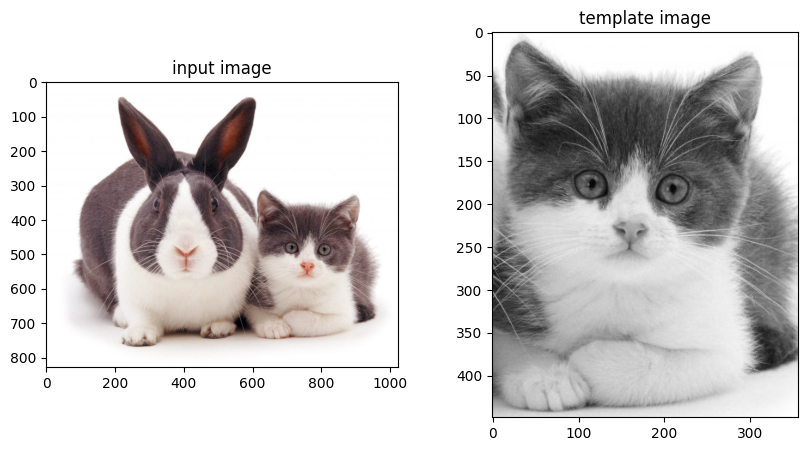

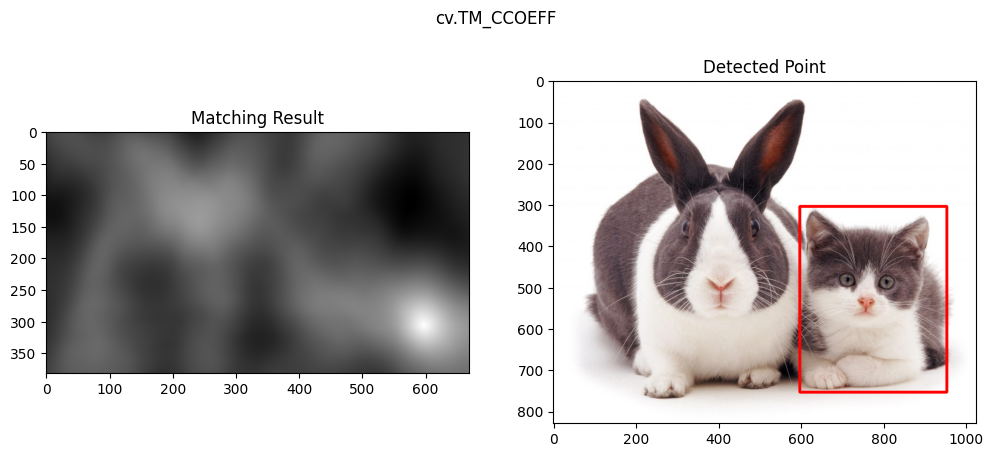

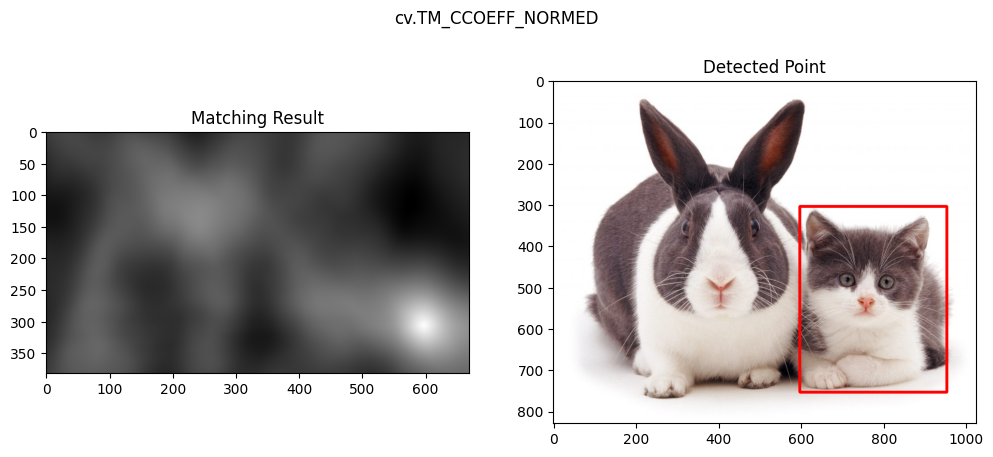

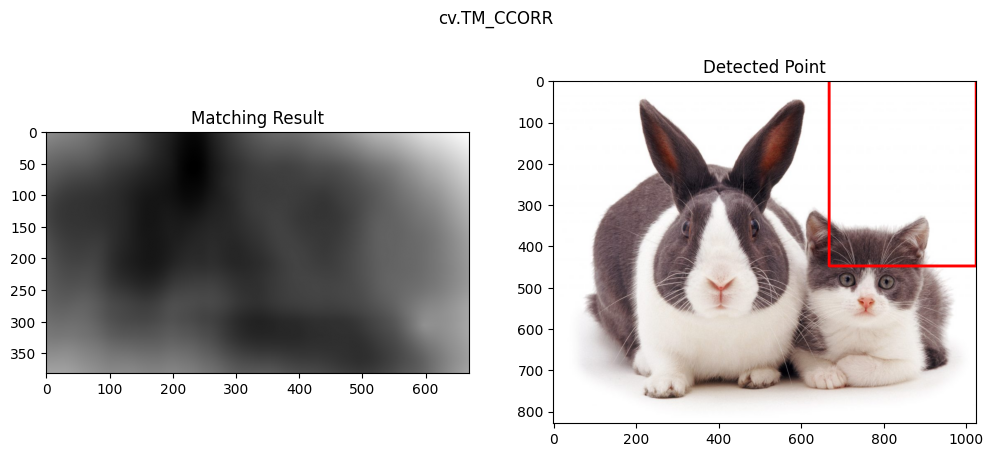

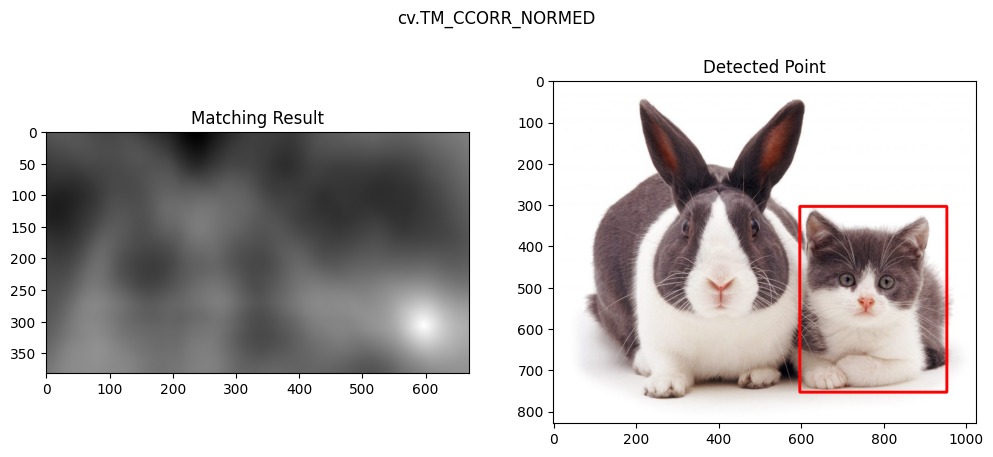

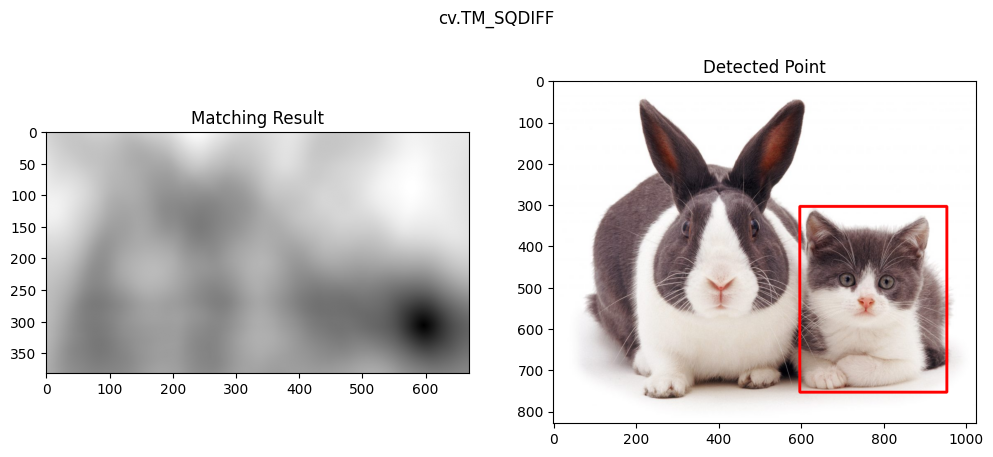

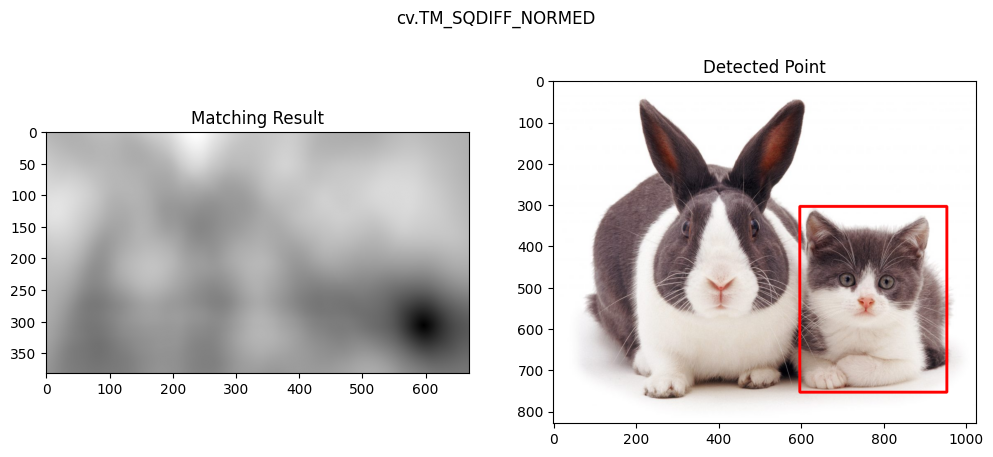

In [7]:
# D1.2 Template Matching OpenCV
citra = cv.imread('/content/drive/MyDrive/PCVK/cats_and_bunnies.jpg')
citra_rgb = cv.cvtColor(citra, cv.COLOR_BGR2RGB)
abu = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)
templ = cv.imread('/content/drive/MyDrive/PCVK/cat2_template.jpg', 0)
h, w = templ.shape

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(citra_rgb)
ax[0].set_title('input image')
ax[1].imshow(templ, cmap='gray')
ax[1].set_title('template image')
plt.show()

metode = [('cv.TM_CCOEFF', cv.TM_CCOEFF),
          ('cv.TM_CCOEFF_NORMED', cv.TM_CCOEFF_NORMED),
          ('cv.TM_CCORR', cv.TM_CCORR),
          ('cv.TM_CCORR_NORMED', cv.TM_CCORR_NORMED),
          ('cv.TM_SQDIFF', cv.TM_SQDIFF),
          ('cv.TM_SQDIFF_NORMED', cv.TM_SQDIFF_NORMED)]

for nama, m in metode:
    res = cv.matchTemplate(abu, templ, m)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)
    kiri_atas = min_loc if m in (cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED) else max_loc
    kotak = citra_rgb.copy()
    cv.rectangle(kotak, kiri_atas, (kiri_atas[0] + w, kiri_atas[1] + h), (255, 0, 0), 5)
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].imshow(res, cmap='gray')
    ax[0].set_title('Matching Result')
    ax[1].imshow(kotak)
    ax[1].set_title('Detected Point')
    fig.suptitle(nama)
    plt.show()

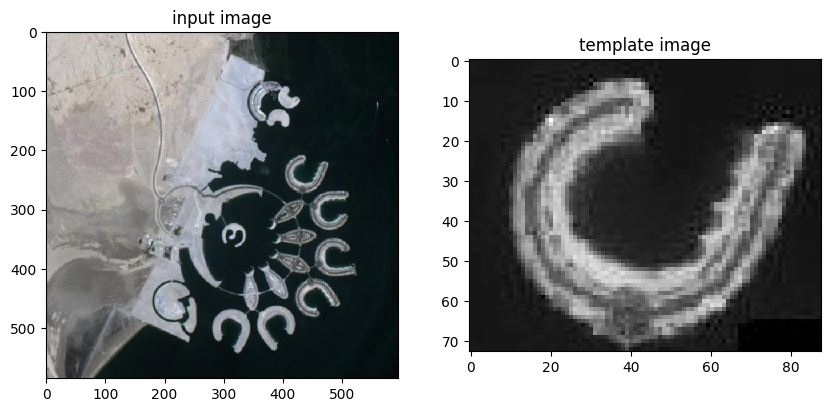

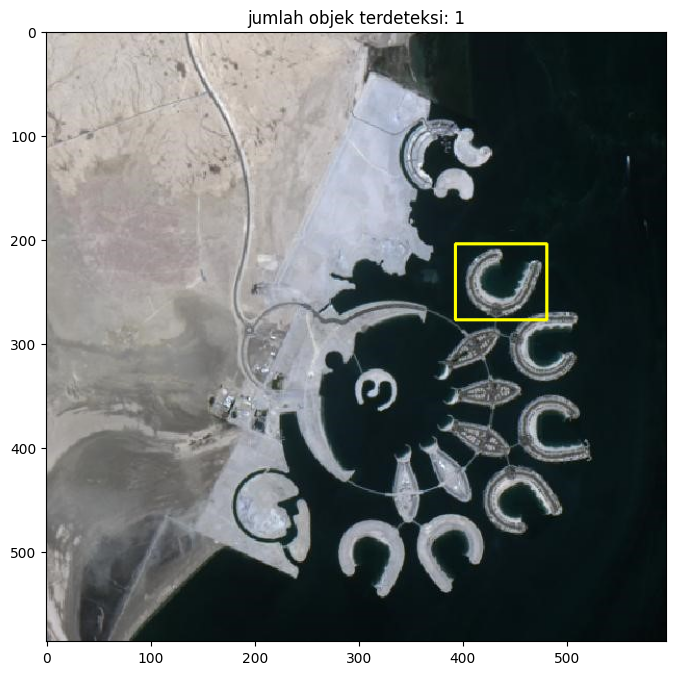

In [8]:
# D1.3 Template Matching Multiple Object Tanpa OpenCV
citra = cv.imread('/content/drive/MyDrive/PCVK/bahrain.jpg')
citra_rgb = cv.cvtColor(citra, cv.COLOR_BGR2RGB)
I = cv.imread('/content/drive/MyDrive/PCVK/bahrain.jpg', 0).astype(np.float64)
T = cv.imread('/content/drive/MyDrive/PCVK/bahrain-template.jpg', 0).astype(np.float64)
H, W = I.shape
h, w = T.shape

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(citra_rgb)
ax[0].set_title('input image')
ax[1].imshow(T, cmap='gray')
ax[1].set_title('template image')
plt.show()

ukuran = (H + h - 1, W + w - 1)
Tz = T - T.mean()
korelasi = np.fft.irfft2(np.fft.rfft2(I, ukuran) * np.fft.rfft2(Tz[::-1, ::-1], ukuran), ukuran)
pembilang = korelasi[h - 1:H, w - 1:W]

ii = np.pad(I, ((1, 0), (1, 0))).cumsum(0).cumsum(1)
ii2 = np.pad(I ** 2, ((1, 0), (1, 0))).cumsum(0).cumsum(1)
kotak_jumlah = lambda a: a[h:, w:] - a[:-h, w:] - a[h:, :-w] + a[:-h, :-w]
jumlah = kotak_jumlah(ii)
jumlah2 = kotak_jumlah(ii2)
varian = np.maximum(jumlah2 - jumlah ** 2 / (h * w), 1e-6)
R = pembilang / np.sqrt(varian * np.sum(Tz ** 2))

ambang = 0.6
kandidat = np.argwhere(R >= ambang)
skor = R[tuple(kandidat.T)]
kandidat = kandidat[np.argsort(-skor)]

terpilih = []
for y, x in kandidat:
    if all(abs(y - yy) > h // 2 or abs(x - xx) > w // 2 for yy, xx in terpilih):
        terpilih.append((y, x))

hasil = citra_rgb.copy()
for y, x in terpilih:
    cv.rectangle(hasil, (int(x), int(y)), (int(x + w), int(y + h)), (255, 255, 0), 2)

plt.figure(figsize=(8, 8))
plt.imshow(hasil)
plt.title('jumlah objek terdeteksi: ' + str(len(terpilih)))
plt.show()

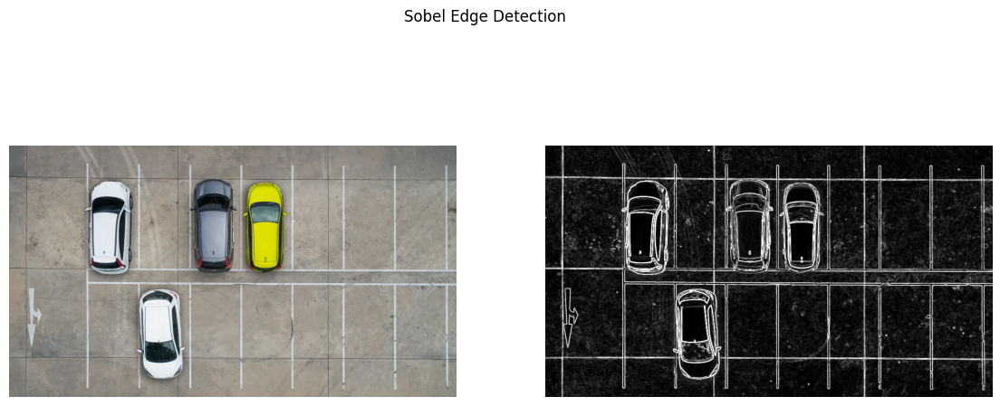

In [9]:
# D1.4a Sobel Edge Detection
mobil = cv.imread('/content/drive/MyDrive/PCVK/car-park.jpg')
abu = cv.cvtColor(mobil, cv.COLOR_BGR2GRAY)
sobel_x = cv.Sobel(abu, cv.CV_64F, 1, 0, ksize=3)
sobel_y = cv.Sobel(abu, cv.CV_64F, 0, 1, ksize=3)
sobel = cv.convertScaleAbs(cv.magnitude(sobel_x, sobel_y))
pasangan(mobil, sobel, 'Sobel Edge Detection')

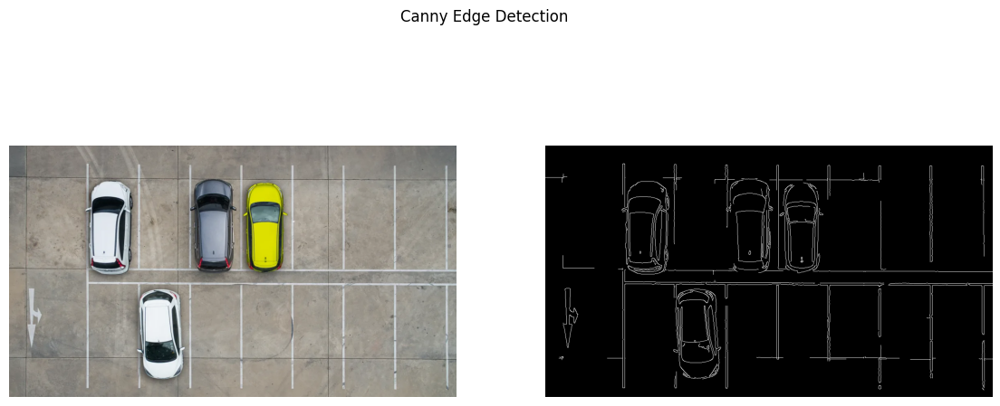

In [11]:
# D1.4b Canny Edge Detection
blur = cv.GaussianBlur(abu, (5, 5), 0)
canny = cv.Canny(blur, 100, 200)
pasangan(mobil, canny, 'Canny Edge Detection')

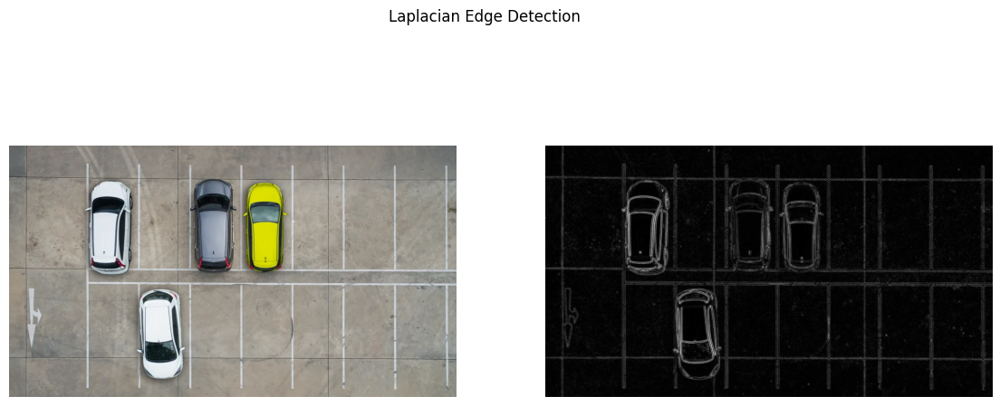

In [12]:
# D1.4c Laplacian Edge Detection
laplacian = cv.convertScaleAbs(cv.Laplacian(blur, cv.CV_64F, ksize=3))
pasangan(mobil, laplacian, 'Laplacian Edge Detection')

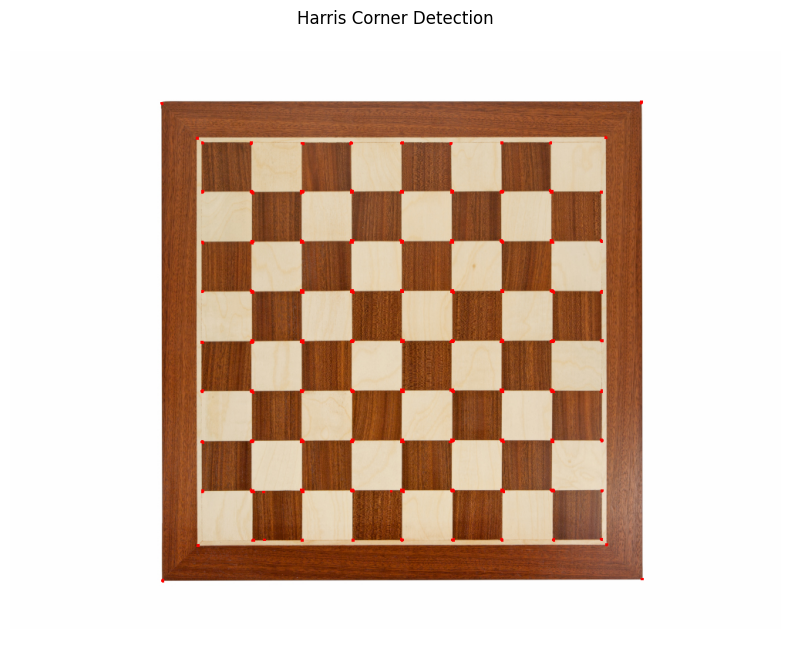

In [13]:
# D1.5a Harris Corner Detection
papan = cv.imread('/content/drive/MyDrive/PCVK/chess-board.jpg')
abu = cv.cvtColor(papan, cv.COLOR_BGR2GRAY)
harris = cv.cornerHarris(np.float32(abu), 2, 3, 0.04)
harris = cv.dilate(harris, None)
hasil_harris = papan.copy()
hasil_harris[harris > 0.01 * harris.max()] = [0, 0, 255]
tampil(hasil_harris, 'Harris Corner Detection')

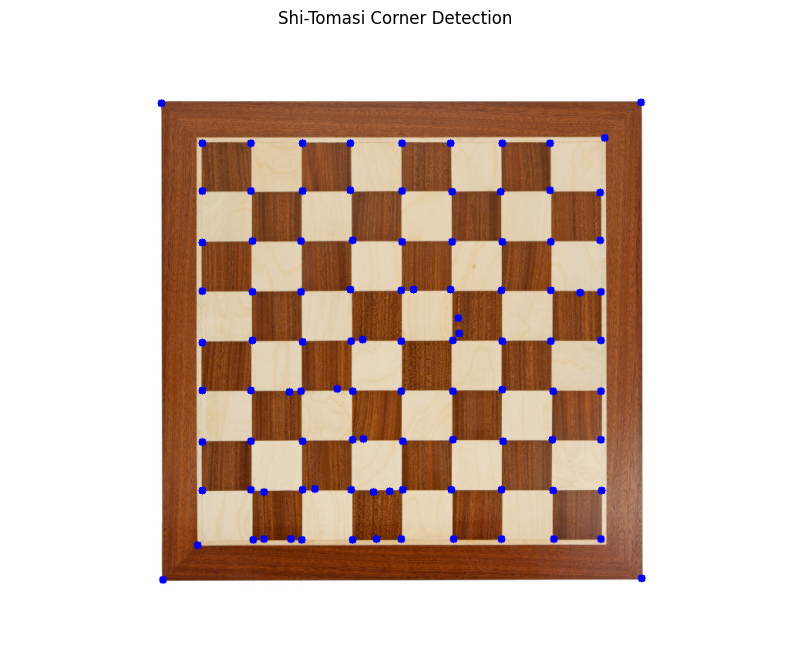

In [14]:
# D1.5b Shi-Tomasi Corner Detection
sudut = cv.goodFeaturesToTrack(abu, 100, 0.01, 10)
hasil_shi = papan.copy()
for s in np.intp(sudut):
    x, y = s.ravel()
    cv.circle(hasil_shi, (int(x), int(y)), 5, (255, 0, 0), -1)
tampil(hasil_shi, 'Shi-Tomasi Corner Detection')

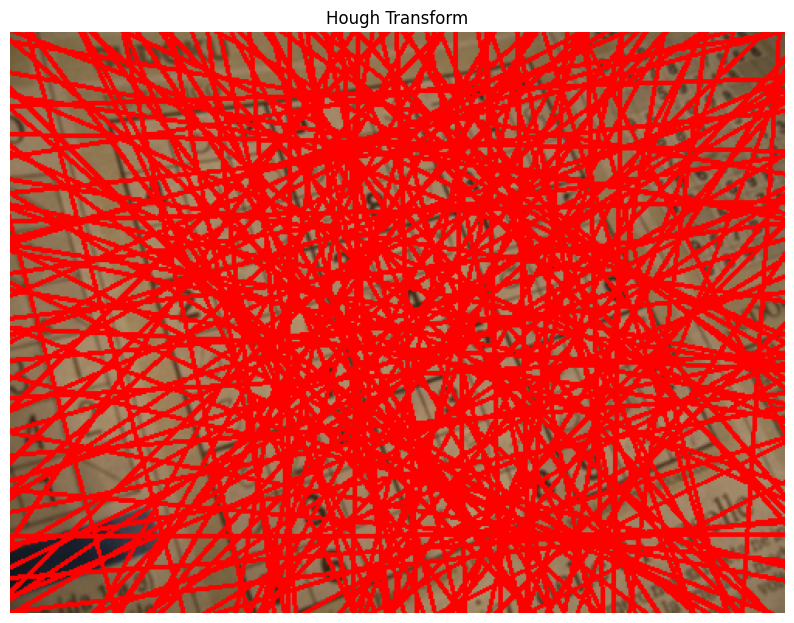

In [16]:
# D1.6 Grid Detection Hough Transform
sudoku = cv.imread('/content/drive/MyDrive/PCVK/sudoku.jpg')
abu = cv.cvtColor(sudoku, cv.COLOR_BGR2GRAY)
tepi = cv.Canny(abu, 50, 150)
kernel = np.ones((3, 3), np.uint8)
dilasi = cv.dilate(tepi, kernel, iterations=1)
erosi = cv.erode(dilasi, kernel, iterations=1)
garis = cv.HoughLines(erosi, 1, np.pi / 180, 120)

def gabung_garis(garis, batas_rho=20, batas_theta=np.pi / 18):
    kelompok = []
    for rho, theta in garis[:, 0]:
        if theta > np.pi - batas_theta:
            rho, theta = -rho, theta - np.pi
        for k in kelompok:
            r0, t0 = np.mean(k, axis=0)
            if abs(rho - r0) < batas_rho and abs(theta - t0) < batas_theta:
                k.append((rho, theta))
                break
        else:
            kelompok.append([(rho, theta)])
    return [np.mean(k, axis=0) for k in kelompok]

hasil = sudoku.copy()
for rho, theta in gabung_garis(garis):
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    p1 = (int(x0 - 2000 * b), int(y0 + 2000 * a))
    p2 = (int(x0 + 2000 * b), int(y0 - 2000 * a))
    cv.line(hasil, p1, p2, (0, 0, 255), 2)
tampil(hasil, 'Hough Transform')

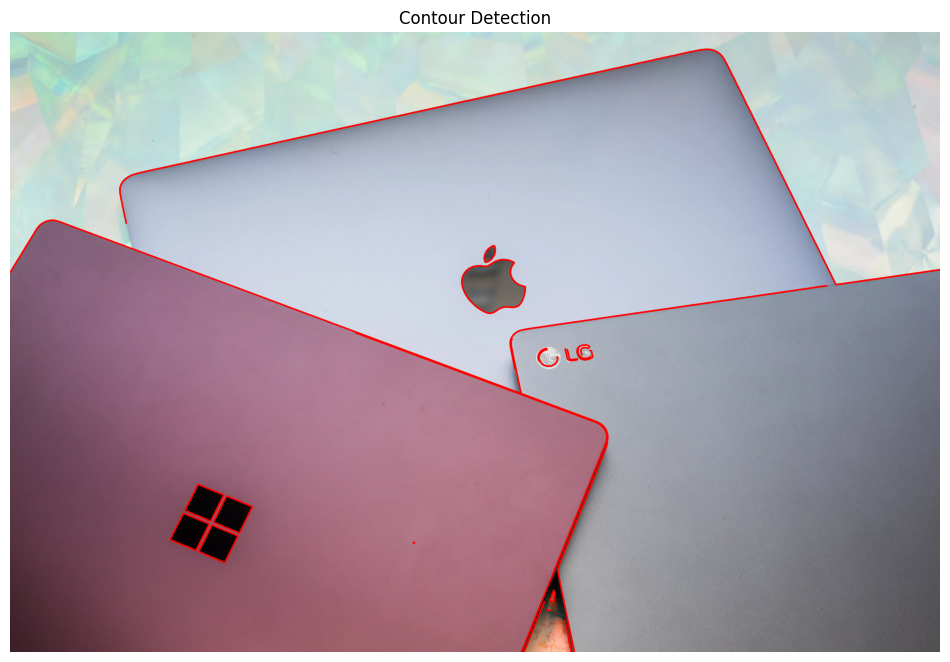

In [17]:
# D1.7 Contour Detection
laptop = cv.imread('/content/drive/MyDrive/PCVK/laptop.jpg')
abu = cv.cvtColor(laptop, cv.COLOR_BGR2GRAY)
blur = cv.GaussianBlur(abu, (7, 7), 0)
tepi = cv.Canny(blur, 50, 150)
kontur, hirarki = cv.findContours(tepi, cv.RETR_TREE, cv.CHAIN_APPROX_SIMPLE)
hasil = laptop.copy()
cv.drawContours(hasil, kontur, -1, (0, 0, 255), 5)
tampil(hasil, 'Contour Detection', size=(12, 10))

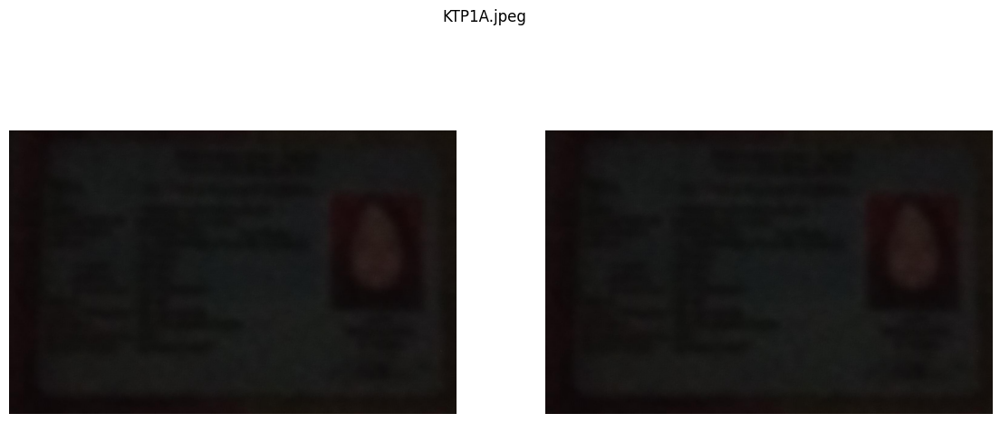

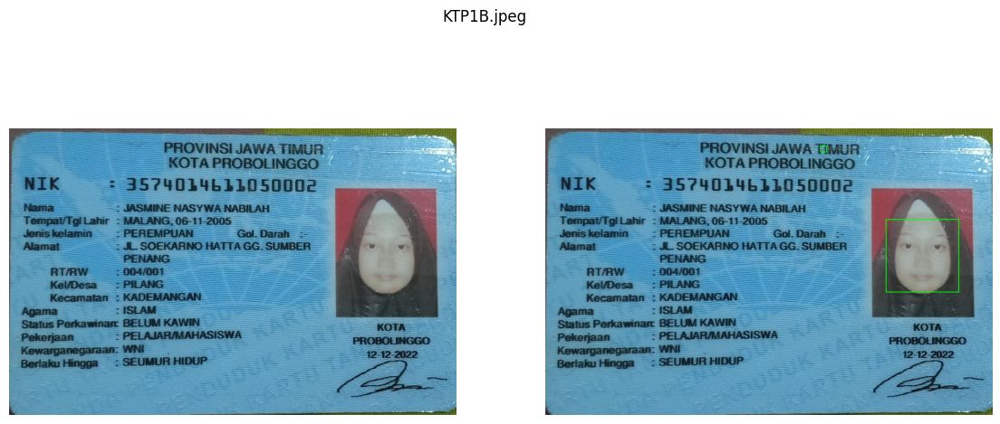

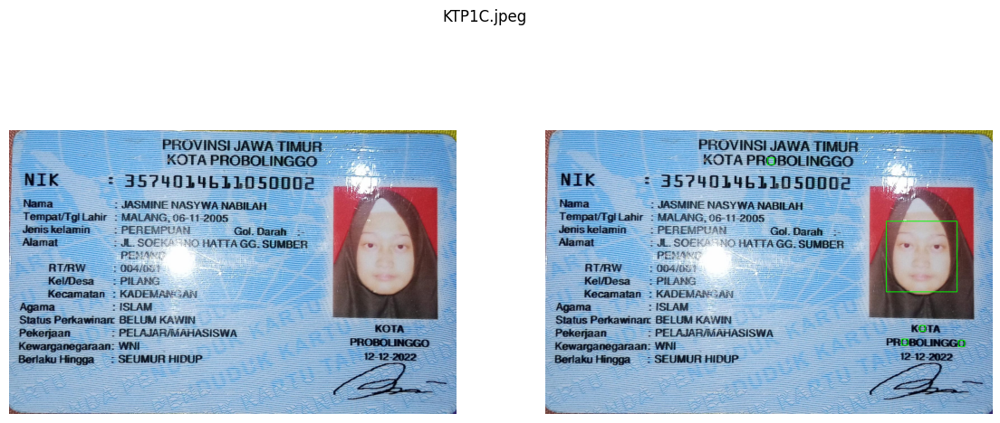

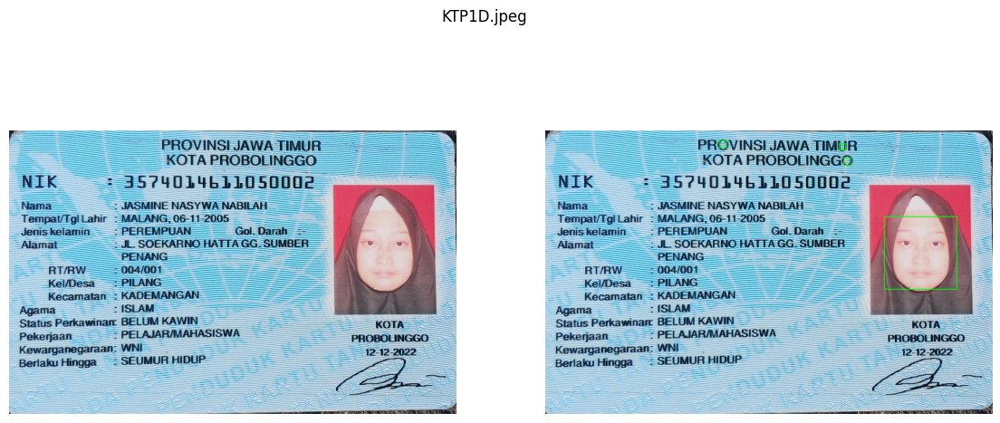

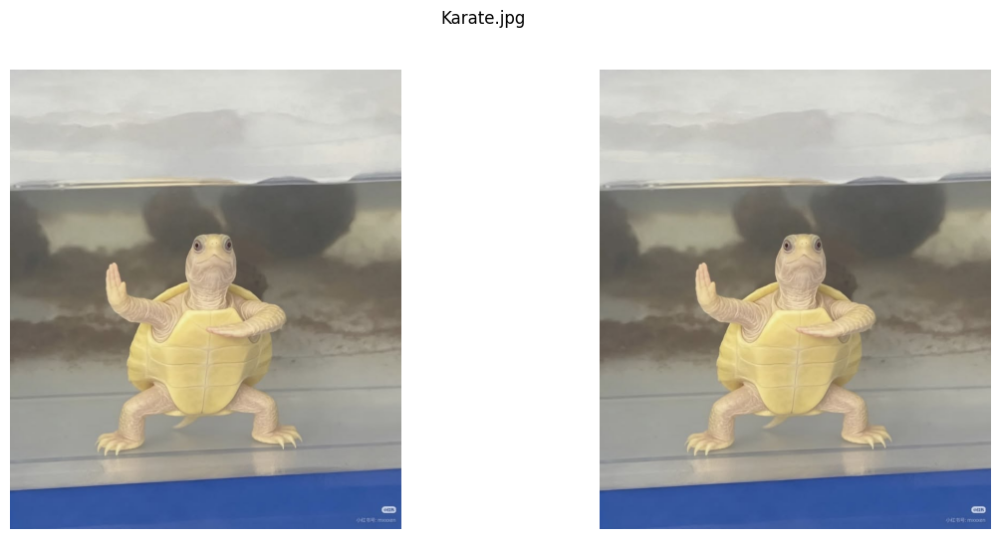

...

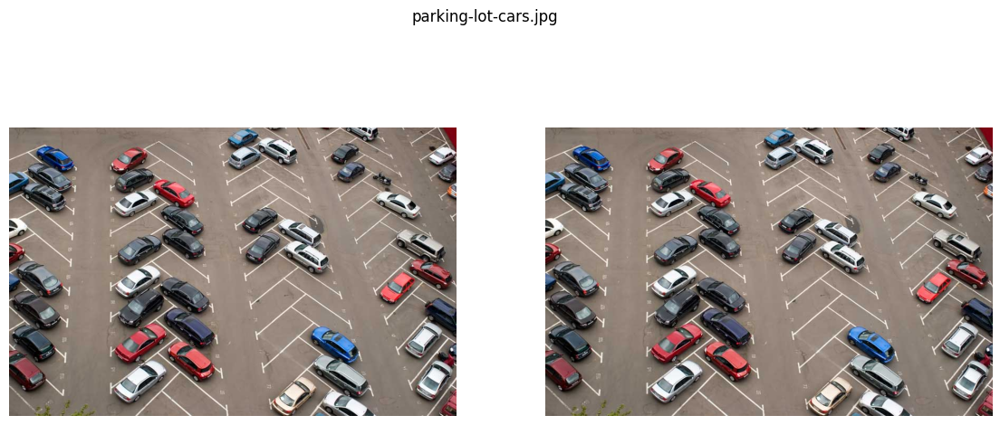

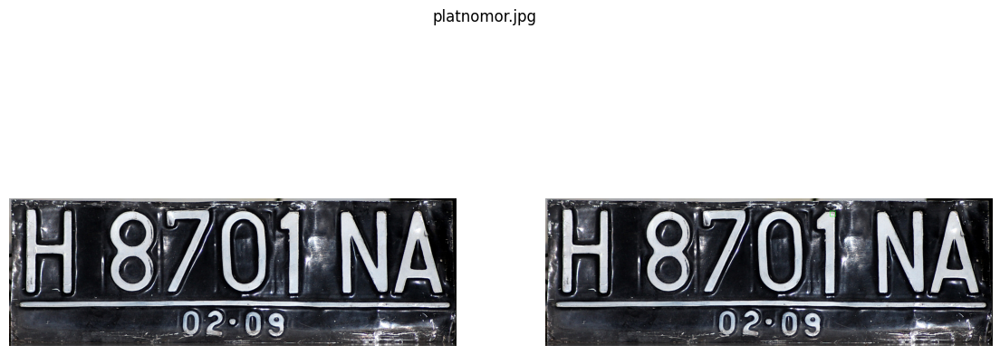

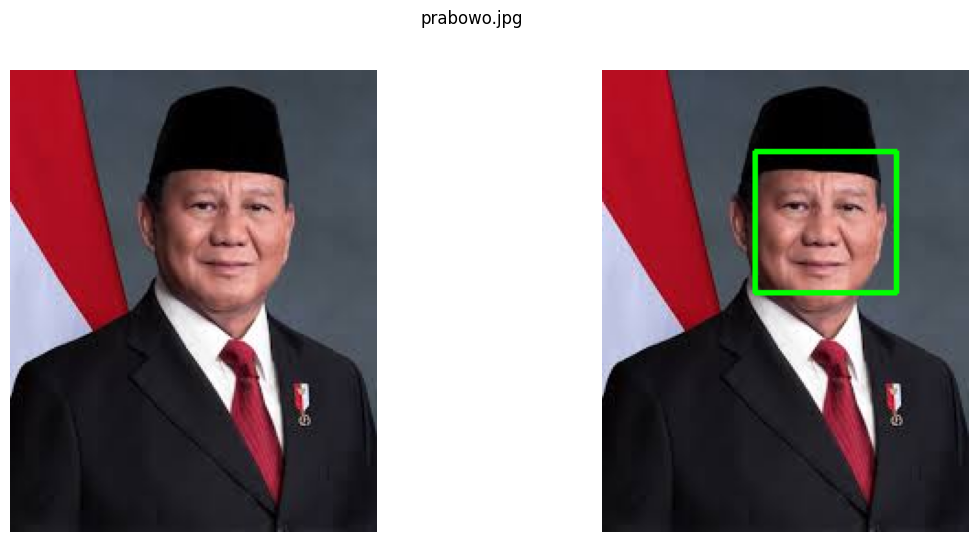

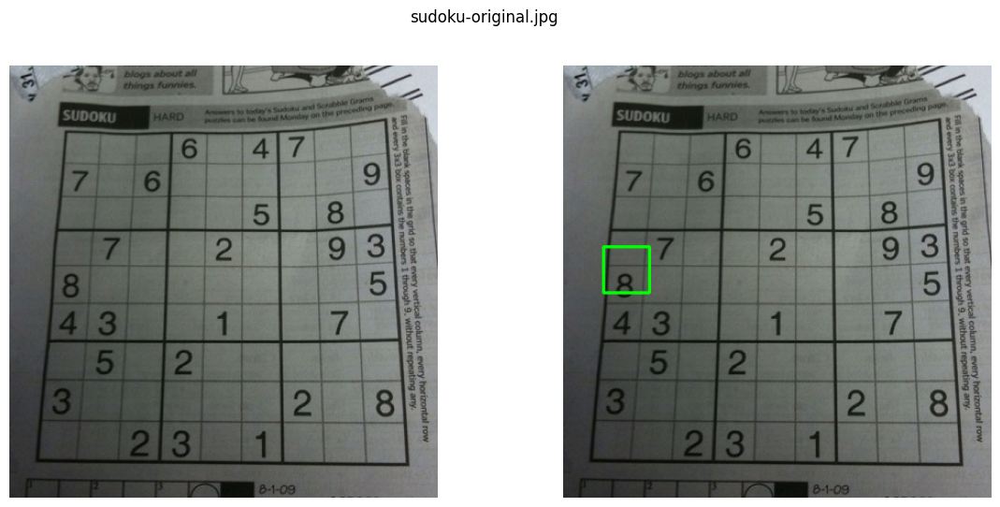

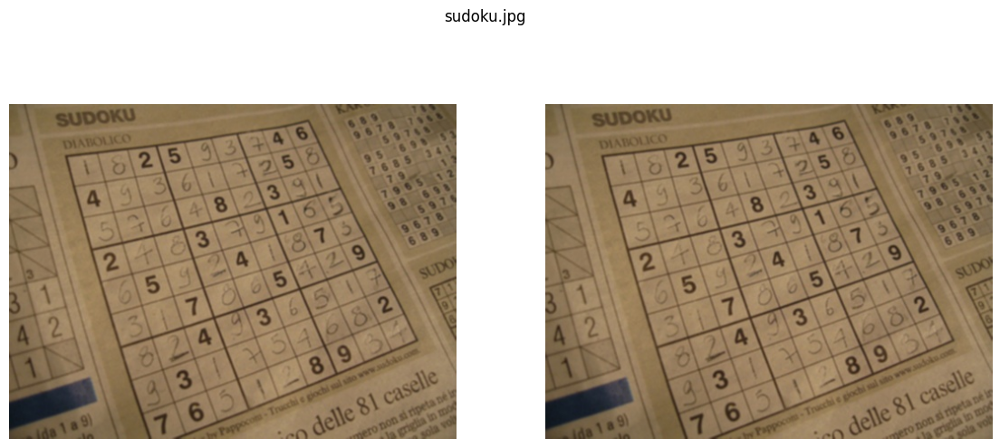

In [18]:
# D2.8 Face Detection
folder_facedet = os.path.dirname('/content/drive/MyDrive/PCVK/prabowo.jpg')
berkas = sorted(f for f in os.listdir(folder_facedet) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
kecuali = ('reeses', 'cereals', 'people', 'ktm')
daftar_wajah = [os.path.join(folder_facedet, f) for f in berkas if not any(k in f.lower() for k in kecuali)]
cascade_wajah = cascade('haarcascade_frontalface_alt.xml')

for p in daftar_wajah:
    asli = cv.imread(p)
    hasil = asli.copy()
    abu = cv.cvtColor(asli, cv.COLOR_BGR2GRAY)
    for (x, y, w, h) in cascade_wajah.detectMultiScale(abu):
        cv.rectangle(hasil, (x, y), (x + w, y + h), (0, 255, 0), 2)
    pasangan(asli, hasil, os.path.basename(p))

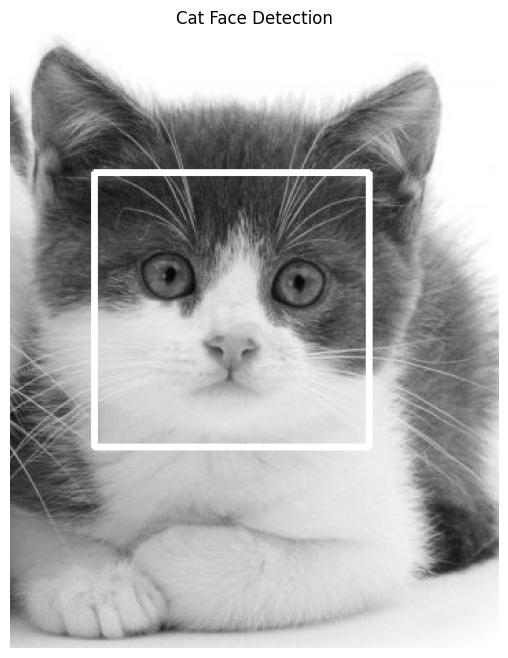

In [20]:
# D2.9 Deteksi Wajah Kucing
kucing = cv.imread('/content/drive/MyDrive/PCVK/cat2_template.jpg', 0)
cascade_kucing = cascade('haarcascade_frontalcatface_extended.xml')
hasil = kucing.copy()
for (x, y, w, h) in cascade_kucing.detectMultiScale(kucing, 1.1, 3):
    cv.rectangle(hasil, (x, y), (x + w, y + h), 255, 3)
tampil(hasil, 'Cat Face Detection')

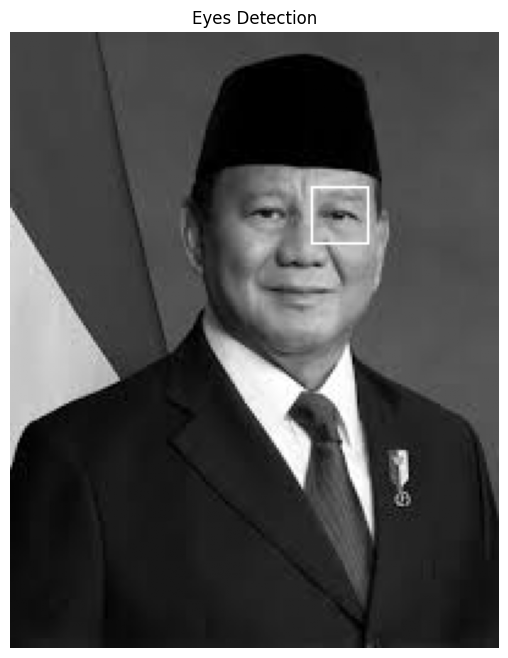

In [21]:
# D2.10 Eyes Detection
prabowo = cv.imread('/content/drive/MyDrive/PCVK/prabowo.jpg', 0)
cascade_mata = cascade('haarcascade_eye.xml')
hasil = prabowo.copy()
for (x, y, w, h) in cascade_wajah.detectMultiScale(prabowo):
    roi = prabowo[y:y + h, x:x + w]
    for (ex, ey, ew, eh) in cascade_mata.detectMultiScale(roi):
        cv.rectangle(hasil, (x + ex, y + ey), (x + ex + ew, y + ey + eh), 255, 1)
tampil(hasil, 'Eyes Detection')

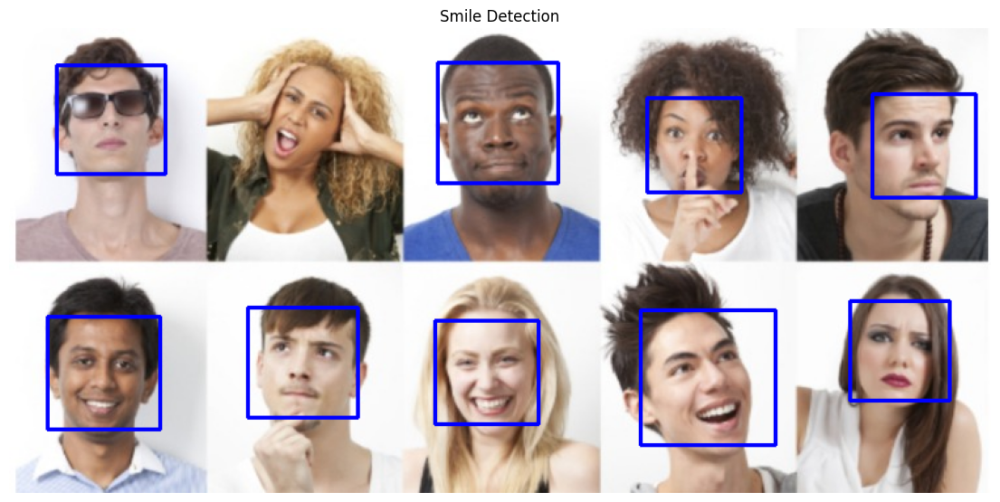

In [23]:
# D2.11 Smile Detection
people = cv.imread('/content/drive/MyDrive/PCVK/people.jpeg')
abu = cv.cvtColor(people, cv.COLOR_BGR2GRAY)
cascade_senyum = cascade('haarcascade_smile.xml')
hasil = people.copy()
for (x, y, w, h) in cascade_wajah.detectMultiScale(abu):
    cv.rectangle(hasil, (x, y), (x + w, y + h), (255, 0, 0), 2)
    roi = abu[y + h // 2:y + h, x:x + w]
    for (sx, sy, sw, sh) in cascade_senyum.detectMultiScale(roi, 1.7, 20):
        cv.rectangle(hasil, (x + sx, y + h // 2 + sy), (x + sx + sw, y + h // 2 + sy + sh), (0, 255, 0), 2)
tampil(hasil, 'Smile Detection', size=(14, 8))

In [24]:
# D2.12 Face Tracking Fungsi Kamera
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import io
import PIL

def js_to_image(js_reply):
    jpeg_bytes = b64decode(js_reply.split(',')[1])
    img_array = np.frombuffer(jpeg_bytes, dtype=np.uint8)
    return cv.imdecode(img_array, flags=1)

def bbox_to_bytes(bbox_array):
    bbox_pil = PIL.Image.fromarray(bbox_array, 'RGBA')
    iobuf = io.BytesIO()
    bbox_pil.save(iobuf, format='png')
    return 'data:image/png;base64,{}'.format(str(b64encode(iobuf.getvalue()), 'utf-8'))

def video_stream():
    js = Javascript('''
    var video;
    var div = null;
    var stream;
    var captureCanvas;
    var imgElement;
    var labelElement;
    var pendingResolve = null;
    var shutdown = false;

    function removeDom() {
        stream.getVideoTracks()[0].stop();
        video.remove();
        div.remove();
        video = null;
        div = null;
        stream = null;
        imgElement = null;
        captureCanvas = null;
        labelElement = null;
    }

    function onAnimationFrame() {
        if (!shutdown) {
            window.requestAnimationFrame(onAnimationFrame);
        }
        if (pendingResolve) {
            var result = "";
            if (!shutdown) {
                captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
                result = captureCanvas.toDataURL('image/jpeg', 0.8);
            }
            var lp = pendingResolve;
            pendingResolve = null;
            lp(result);
        }
    }

    async function createDom() {
        if (div !== null) {
            return stream;
        }
        div = document.createElement('div');
        div.style.border = '2px solid black';
        div.style.padding = '3px';
        div.style.width = '100%';
        div.style.maxWidth = '600px';
        document.body.appendChild(div);

        const modelOut = document.createElement('div');
        modelOut.innerHTML = "<span>Status:</span>";
        labelElement = document.createElement('span');
        labelElement.innerText = 'No data';
        labelElement.style.fontWeight = 'bold';
        modelOut.appendChild(labelElement);
        div.appendChild(modelOut);

        video = document.createElement('video');
        video.style.display = 'block';
        video.width = div.clientWidth - 6;
        video.setAttribute('playsinline', '');
        video.onclick = () => { shutdown = true; };
        stream = await navigator.mediaDevices.getUserMedia({video: {facingMode: "user"}});
        div.appendChild(video);

        imgElement = document.createElement('img');
        imgElement.style.position = 'absolute';
        imgElement.style.zIndex = 1;
        imgElement.onclick = () => { shutdown = true; };
        div.appendChild(imgElement);

        const instruction = document.createElement('div');
        instruction.innerHTML = '<span style="color: red; font-weight: bold;">Klik di sini atau pada video untuk berhenti</span>';
        div.appendChild(instruction);
        instruction.onclick = () => { shutdown = true; };

        video.srcObject = stream;
        await video.play();

        captureCanvas = document.createElement('canvas');
        captureCanvas.width = 640;
        captureCanvas.height = 480;
        window.requestAnimationFrame(onAnimationFrame);
        return stream;
    }

    async function stream_frame(label, imgData) {
        if (shutdown) {
            removeDom();
            shutdown = false;
            return '';
        }
        var preCreate = Date.now();
        stream = await createDom();
        var preShow = Date.now();
        if (label != "") {
            labelElement.innerHTML = label;
        }
        if (imgData != "") {
            var videoRect = video.getClientRects()[0];
            imgElement.style.top = videoRect.top + "px";
            imgElement.style.left = videoRect.left + "px";
            imgElement.style.width = videoRect.width + "px";
            imgElement.style.height = videoRect.height + "px";
            imgElement.src = imgData;
        }
        var preCapture = Date.now();
        var result = await new Promise(function(resolve, reject) {
            pendingResolve = resolve;
        });
        shutdown = false;
        return {'create': preShow - preCreate,
                'show': preCapture - preShow,
                'capture': Date.now() - preCapture,
                'img': result};
    }
    ''')
    display(js)

def video_frame(label, bbox):
    return eval_js('stream_frame("{}", "{}")'.format(label, bbox))

In [26]:
# D2.12 Face Tracking Jalankan
video_stream()
label_html = 'Face Tracking'
bbox = ''
while True:
    js_reply = video_frame(label_html, bbox)
    if not js_reply:
        break
    frame = js_to_image(js_reply['img'])
    bbox_array = np.zeros([480, 640, 4], dtype=np.uint8)
    abu = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
    for (x, y, w, h) in cascade_wajah.detectMultiScale(abu):
        bbox_array = cv.rectangle(bbox_array, (x, y), (x + w, y + h), (255, 0, 0), 2)
    bbox_array[:, :, 3] = (bbox_array.max(axis=2) > 0).astype(int) * 255
    bbox = bbox_to_bytes(bbox_array)

<IPython.core.display.Javascript object>

/tmp/ipykernel_2368/949719271.py:14: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  bbox_pil = PIL.Image.fromarray(bbox_array, 'RGBA')


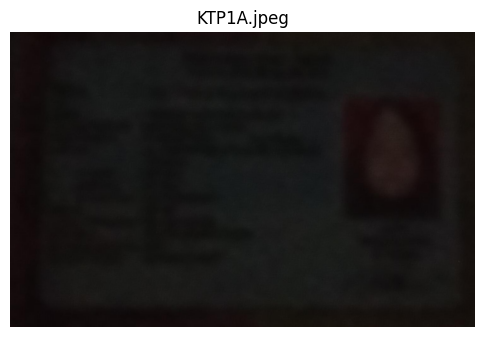

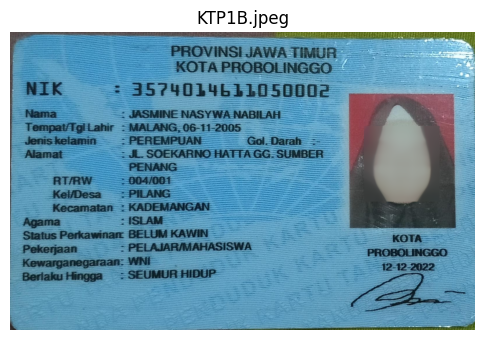

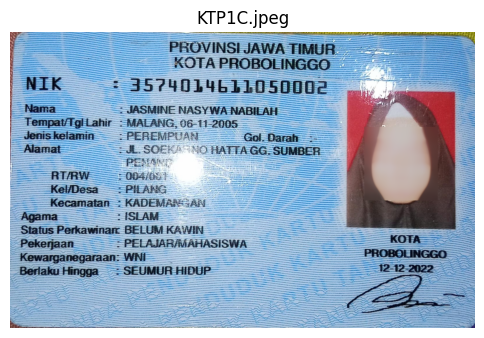

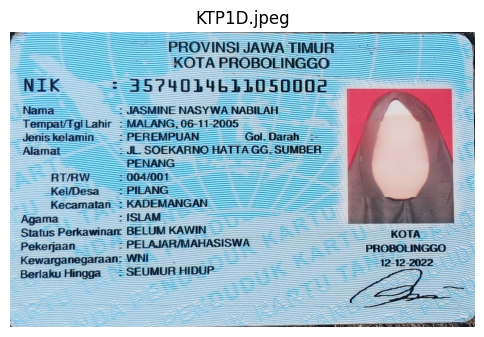

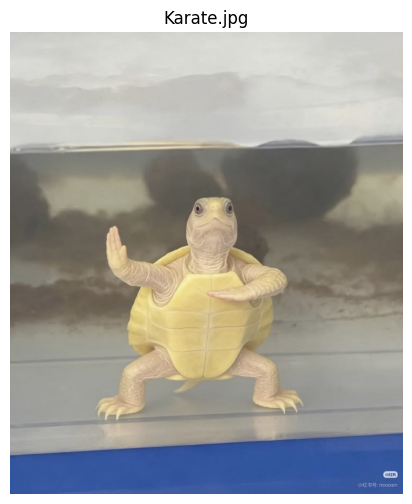

...

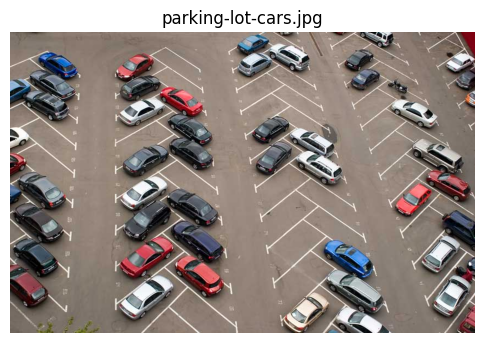

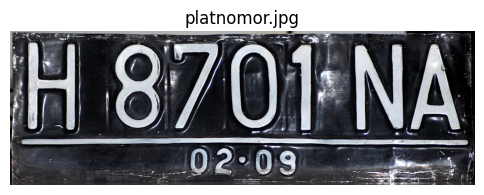

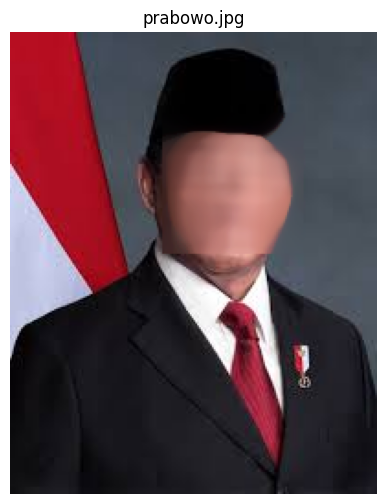

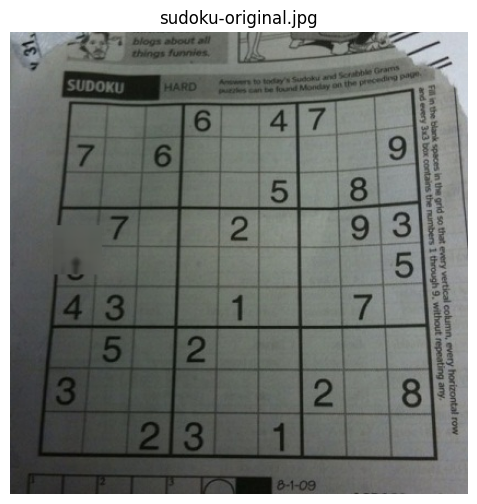

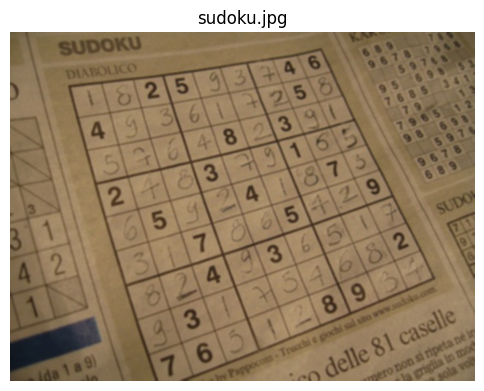

In [27]:
# D2.13 Blurring Wajah
for p in daftar_wajah:
    gambar = cv.imread(p)
    abu = cv.cvtColor(gambar, cv.COLOR_BGR2GRAY)
    for (x, y, w, h) in cascade_wajah.detectMultiScale(abu):
        k = max(5, w // 3) | 1
        gambar[y:y + h, x:x + w] = cv.medianBlur(gambar[y:y + h, x:x + w], k)
    tampil(gambar, os.path.basename(p), size=(6, 6))

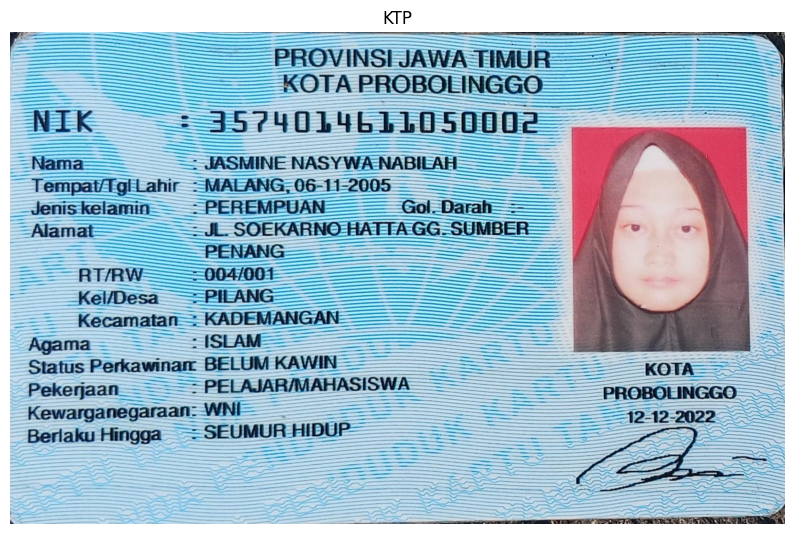

In [28]:
# D2.14a Gambar KTM
nama_ktm = 'ktp.jpg'
nama_scene = 'ktp_dan_barang.jpg'
ktp = cv.imread('/content/drive/MyDrive/PCVK/KTP1D.jpeg')
tampil(ktp, 'KTP')

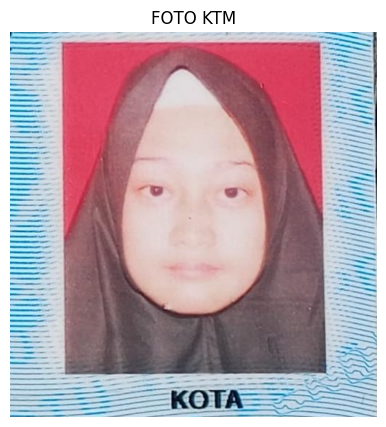

In [29]:
# D2.14b Foto KTM
abu_ktm = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)
wajah = cascade_wajah.detectMultiScale(abu_ktm, 1.05, 3)
x, y, w, h = max(wajah, key=lambda r: r[2] * r[3])
x1 = max(0, x - int(0.5 * w))
x2 = min(ktp.shape[1], x + w + int(0.5 * w))
y1 = max(0, y - int(0.5 * h))
y2 = min(ktp.shape[0], y + h + int(0.6 * h))
foto_ktm = ktp[y1:y2, x1:x2]
tampil(foto_ktm, 'FOTO KTM', size=(5, 5))

jumlah match bagus: 14752


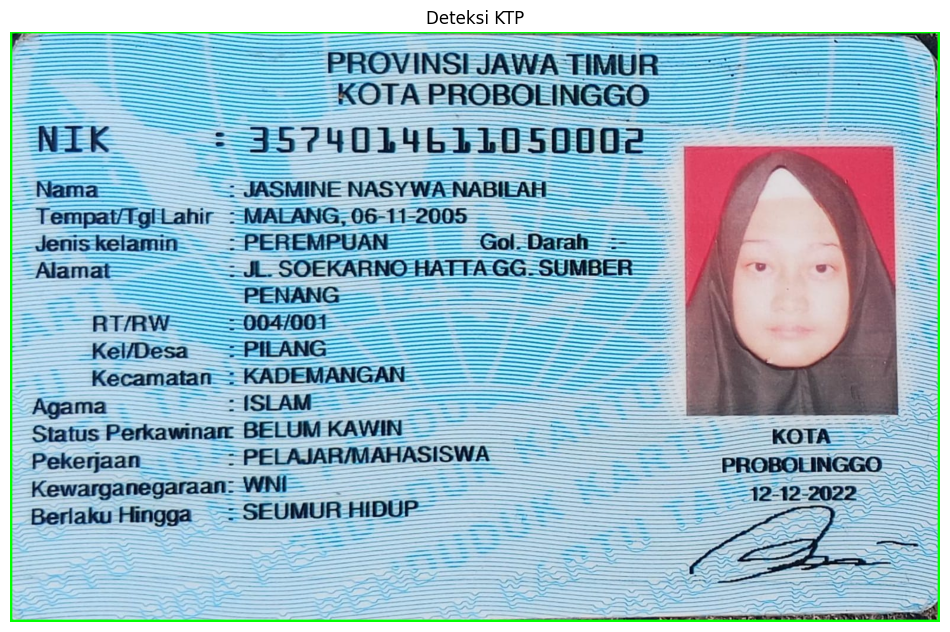

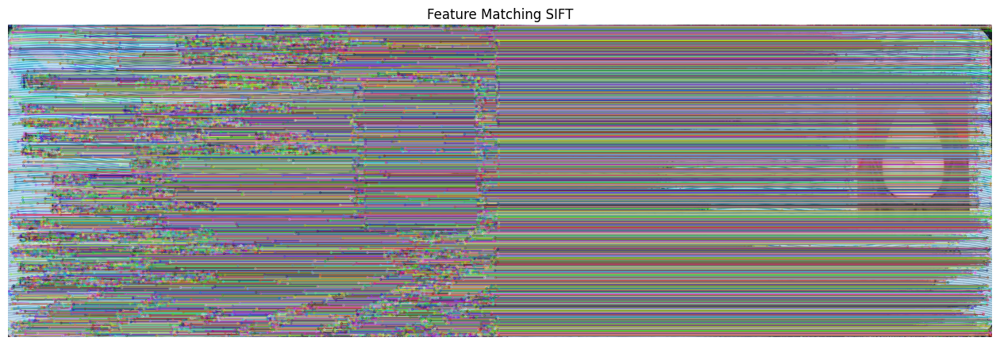

In [31]:
# D2.14c Deteksi KTP Feature Matching
scene = cv.imread('/content/drive/MyDrive/PCVK/KTP1D.jpeg')
abu_scene = cv.cvtColor(scene, cv.COLOR_BGR2GRAY)
sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(abu_ktm, None)
kp2, des2 = sift.detectAndCompute(abu_scene, None)
bf = cv.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)
bagus = [m for m, n in (p for p in matches if len(p) == 2) if m.distance < 0.75 * n.distance]
print('jumlah match bagus:', len(bagus))

hasil = scene.copy()
if len(bagus) >= 10:
    src = np.float32([kp1[m.queryIdx].pt for m in bagus]).reshape(-1, 1, 2)
    dst = np.float32([kp2[m.trainIdx].pt for m in bagus]).reshape(-1, 1, 2)
    M, mask = cv.findHomography(src, dst, cv.RANSAC, 5.0)
    hk, wk = abu_ktm.shape
    sudut = np.float32([[0, 0], [0, hk - 1], [wk - 1, hk - 1], [wk - 1, 0]]).reshape(-1, 1, 2)
    proyeksi = cv.perspectiveTransform(sudut, M)
    hasil = cv.polylines(hasil, [np.int32(proyeksi)], True, (0, 255, 0), 5)

tampil(hasil, 'Deteksi KTP', size=(12, 8))
pencocokan = cv.drawMatches(ktp, kp1, scene, kp2, bagus, None, flags=2)
tampil(pencocokan, 'Feature Matching SIFT', size=(16, 8))

In [34]:
# D3 Persiapan Data Training
DATADIR = os.path.join(PCVK, 'training')
width, height = 100, 100

dirs = sorted(os.listdir(DATADIR))
training_data = []

for char_name in dirs:
    path = os.path.join(DATADIR, char_name)
    class_number = dirs.index(char_name)
    for img in tqdm(os.listdir(path), desc=char_name):
        try:
            img_array = cv.imread(os.path.join(path, img), cv.IMREAD_GRAYSCALE)
            new_array = cv.resize(img_array, (width, height))
            training_data.append([new_array, class_number])
        except Exception:
            pass

random.shuffle(training_data)

X, Y = [], []
for feature, label in training_data:
    X.append(feature)
    Y.append(label)

X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

pickle.dump(X, open("X.pickle", "wb"))
pickle.dump(Y, open("Y.pickle", "wb"))
pickle.dump(dirs, open("kelas.pickle", "wb"))

print("jumlah data :", len(training_data))
print("jumlah kelas:", len(dirs), dirs)

Bitter_Gourd: 100%|██████████| 1000/1000 [00:15<00:00, 64.93it/s]

jumlah data : 2000
jumlah kelas: 2 ['Bean', 'Bitter_Gourd']


In [35]:
# D3 Training Data
from keras.layers import (Input, Conv2D, MaxPooling2D,
                          Flatten, Dense, ZeroPadding2D)
from keras.models import Model
from keras.optimizers import Adam
from keras.utils import to_categorical

X = pickle.load(open("X.pickle", "rb"))
Y = pickle.load(open("Y.pickle", "rb"))

Y = to_categorical(Y)
X = X / 255.0
width, height = 100, 100
jumlah_kelas = Y.shape[1]

inputs = Input(shape=(width, height, 1))
conv_layer = ZeroPadding2D(padding=(2, 2))(inputs)
conv_layer = Conv2D(16, (5, 5), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = Conv2D(32, (3, 3), strides=(1, 1), activation='relu')(conv_layer)
conv_layer = MaxPooling2D((2, 2))(conv_layer)
conv_layer = Conv2D(64, (3, 3), strides=(1, 1), activation='relu')(conv_layer)

flaten = Flatten()(conv_layer)
fc_layer = Dense(256, activation='relu')(flaten)
fc_layer = Dense(64, activation='relu')(fc_layer)
outputs = Dense(jumlah_kelas, activation='softmax')(fc_layer)

model = Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

riwayat = model.fit(X, Y, epochs=20, verbose=1, validation_split=0.2)
model.save('anpr.keras')

print("akurasi training :", riwayat.history['accuracy'][-1])
print("akurasi validasi :", riwayat.history['val_accuracy'][-1])

Epoch 1/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 34s 653ms/step - accuracy: 0.5956 - loss: 0.6631 - val_accuracy: 0.7225 - val_loss: 0.5862
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 38s 587ms/step - accuracy: 0.7319 - loss: 0.5578 - val_accuracy: 0.7825 - val_loss: 0.5093
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 28s 556ms/step - accuracy: 0.8100 - loss: 0.4712 - val_accuracy: 0.7750 - val_loss: 0.4522
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 28s 561ms/step - accuracy: 0.8419 - loss: 0.4018 - val_accuracy: 0.8075 - val_loss: 0.4063
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 43s 603ms/step - accuracy: 0.8788 - loss: 0.3245 - val_accuracy: 0.8600 - val_loss: 0.3448
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 38s 550ms/step - accuracy: 0.8950 - loss: 0.2694 - val_accuracy: 0.8525 - val_loss: 0.3339
Epoch 7/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 27s 533ms/step - accuracy: 0.9112 - loss: 0.2413 - val_accuracy: 0.8825 - val_loss: 0.2985
Epoch 8/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 42s 552ms/step - accuracy: 0.9275 - loss: 0.1868 - val_accu

In [36]:
# D3 Testing Data
import tensorflow as tf

data_dir_testing = os.path.join(PCVK, 'testing')
width, height = 100, 100

model = tf.keras.models.load_model("anpr.keras")
dirs = pickle.load(open("kelas.pickle", "rb"))

for car in sorted(os.listdir(data_dir_testing)):
    temp = ""
    folder = os.path.join(data_dir_testing, car)
    for char_img in sorted(os.listdir(folder)):
        img_array = cv.imread(os.path.join(folder, char_img), cv.IMREAD_GRAYSCALE)
        new_array = cv.resize(img_array, (width, height))
        new_array = new_array.reshape(-1, width, height, 1) / 255.0
        prediction = model.predict(new_array, verbose=0)
        temp += dirs[np.argmax(prediction[0])]
    print("folder name: {} no: {}".format(car, temp))

folder name: Bean no: BeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBitter_GourdBeanBitter_GourdBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBitter_GourdBeanBeanBeanBeanBeanBeanBitter_GourdBeanBeanBeanBeanBeanBeanBitter_GourdBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBitter_GourdBeanBitter_GourdBitter_GourdBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBitter_GourdBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBitter_GourdBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBitter_GourdBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBitter_GourdBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBeanBean
folder name: Bitter_Gourd no: Bitter_GourdBitter_GourdBitter_GourdBitter_GourdBit